
# 08. PepBERT Ablation Study

## Objective

Evaluate the contributions of pretrained weights and encoder fine-tuning to MIC prediction performance.

## Experimental Design

Three training strategies are compared:

- **Random Initialization**: Train the encoder and regression head from randomly initialized weights.
- **Frozen PepBERT**: Freeze the pretrained encoder and train only the regression head.
- **Fine-tuned PepBERT**: Use the previously trained models from Notebook 05 and evaluated in Notebook 07.

## Model Configurations

| Dataset | Pooling | FC Layers | Dropout |
|---|---|---|---|
| EC | SOS | 1 | 0.0 |
| EC | Mean | 3 | 0.1 |
| SA | SOS | 2 | 0.3 |
| SA | Mean | 1 | 0.0 |

## Training and Evaluation

- Learning rates: 1e-5, 3e-5, 1e-4
- Weight decay: 0.01
- Random seeds: 42, 43, 44, 45, 46
- Model selection: Mean validation MSE across five seeds
- Evaluation metrics: MSE, RMSE, MAE, R², PCC, KTC

## Outputs

All new checkpoints, training histories, predictions, metrics, and figures are saved separately under:

- `models/pepbert/ablation/`
- `results/pepbert_ablation/`

Existing fine-tuned models and evaluation results are preserved.


In [17]:
from pathlib import Path
import sys
import random
import json

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from tqdm.auto import tqdm

# Project paths
ROOT = Path.cwd()
sys.path.insert(0, str(ROOT))

DATA_DIR = ROOT / "data"
RESULT_DIR = ROOT / "results" / "pepbert_ablation"
MODEL_DIR = ROOT / "models" / "pepbert" / "ablation"

# Output directories
for folder in [
    RESULT_DIR,
    RESULT_DIR / "training_history",
    RESULT_DIR / "predictions",
    RESULT_DIR / "figures",
    MODEL_DIR / "frozen",
    MODEL_DIR / "random",
]:
    folder.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"Project: {ROOT}")
print(f"Device: {DEVICE}")
print(f"Results: {RESULT_DIR}")
print(f"Models: {MODEL_DIR}")


Project: c:\Users\jinwo\Desktop\PepBert_REV
Device: cuda
Results: c:\Users\jinwo\Desktop\PepBert_REV\results\pepbert_ablation
Models: c:\Users\jinwo\Desktop\PepBert_REV\models\pepbert\ablation


In [29]:

# Experimental configurations
CONFIGS = {
    ("EC", "SOS"): {"fc_layers": 1, "dropout": 0.0, "weight_decay": 0.01},
    ("EC", "Mean"): {"fc_layers": 3, "dropout": 0.1, "weight_decay": 0.01},
    ("SA", "SOS"): {"fc_layers": 2, "dropout": 0.3, "weight_decay": 0.01},
    ("SA", "Mean"): {"fc_layers": 1, "dropout": 0.0, "weight_decay": 0.01},
}

# Learning rates by ablation mode
LEARNING_RATES = {
    "frozen": [1e-4, 3e-4, 1e-3],
    "random": [3e-5, 1e-4, 3e-4],
}

SEEDS = [42, 43, 44, 45, 46]
ABLATION_MODES = ["frozen", "random"]

MAX_EPOCHS = 500
PATIENCE = 30

# Save experiment configuration
experiment_config = {
    "models": [
        {
            "dataset": target,
            "pooling": pooling,
            **params,
        }
        for (target, pooling), params in CONFIGS.items()
    ],
    "learning_rates": LEARNING_RATES,
    "seeds": SEEDS,
    "ablation_modes": ABLATION_MODES,
    "max_epochs": MAX_EPOCHS,
    "patience": PATIENCE,
    "selection_metric": "validation_mse",
}

with open(RESULT_DIR / "experiment_config.json", "w", encoding="utf-8") as f:
    json.dump(experiment_config, f, indent=2)

print(pd.DataFrame([
    {"Dataset": target, "Pooling": pooling, **params}
    for (target, pooling), params in CONFIGS.items()
]))

total_runs = (
    len(CONFIGS)
    * len(SEEDS)
    * sum(len(LEARNING_RATES[mode]) for mode in ABLATION_MODES)
)

print(f"\nTotal training runs: {total_runs}")
print("Learning rates:", LEARNING_RATES)
print(f"Max Epochs: {MAX_EPOCHS} | Patience: {PATIENCE}")


  Dataset Pooling  fc_layers  dropout  weight_decay
0      EC     SOS          1      0.0          0.01
1      EC    Mean          3      0.1          0.01
2      SA     SOS          2      0.3          0.01
3      SA    Mean          1      0.0          0.01

Total training runs: 120
Learning rates: {'frozen': [0.0001, 0.0003, 0.001], 'random': [3e-05, 0.0001, 0.0003]}
Max Epochs: 500 | Patience: 30


In [19]:

from src.pepbert import PepBERTRegressor
from src.pepbert_pretrained import build_pretrained_encoder

def build_ablation_model(
    mode, target, pooling, seed,
    model_module, pretrained_config, tokenizer, pretrained_weights
):
    # Set random seed
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    config = CONFIGS[(target, pooling)]

    if mode == "frozen":
        encoder = build_pretrained_encoder(
            model_module,
            pretrained_config,
            tokenizer,
            pretrained_weights
        )

        for param in encoder.parameters():
            param.requires_grad = False

        encoder.eval()

    elif mode == "random":
        encoder = model_module.build_transformer(
            src_vocab_size=tokenizer.get_vocab_size(),
            src_seq_len=pretrained_config["seq_len"],
            d_model=pretrained_config["d_model"]
        )

    else:
        raise ValueError(f"Unknown mode: {mode}")

    model = PepBERTRegressor(
        encoder=encoder,
        hidden_size=pretrained_config["d_model"],
        pooling=pooling.lower(),
        fc_layers=config["fc_layers"],
        dropout=config["dropout"]
    )

    return model.to(DEVICE)


In [20]:

from src.pepbert_pretrained import load_pretrained_pepbert

# Load pretrained PepBERT components
model_module, pretrained_config, tokenizer, pretrained_weights = (
    load_pretrained_pepbert()
)

print("PepBERT loaded successfully")
print(f"Vocabulary size: {tokenizer.get_vocab_size()}")
print(f"Hidden size: {pretrained_config['d_model']}")
print(f"Maximum sequence length: {pretrained_config['seq_len']}")


PepBERT loaded successfully
Vocabulary size: 29
Hidden size: 320
Maximum sequence length: 52


In [21]:
# Load final datasets
datasets = {}

for target in ["EC", "SA"]:
    for split in ["Train", "Test"]:
        path = DATA_DIR / f"{target}_{split}.csv"
        df = pd.read_csv(path)

        # Check required columns
        required = {"sequence", "pMIC"}
        if not required.issubset(df.columns):
            raise ValueError(f"Missing columns in {path.name}")

        datasets[(target, split)] = df

        print(f"{target} {split}: {len(df):,} peptides")


EC Train: 7,583 peptides
EC Test: 843 peptides
SA Train: 6,592 peptides
SA Test: 733 peptides


In [22]:

from src.ml import load_validation_split

# Load existing train/validation splits
validation_splits = {}

for target in ["EC", "SA"]:
    for seed in SEEDS:
        train_idx, val_idx = load_validation_split(target, seed)

        validation_splits[(target, seed)] = (train_idx, val_idx)

        print(
            f"{target} | Seed {seed} | "
            f"Train: {len(train_idx):,} | "
            f"Validation: {len(val_idx):,}"
        )


EC | Seed 42 | Train: 6,824 | Validation: 759
EC | Seed 43 | Train: 6,824 | Validation: 759
EC | Seed 44 | Train: 6,824 | Validation: 759
EC | Seed 45 | Train: 6,824 | Validation: 759
EC | Seed 46 | Train: 6,824 | Validation: 759
SA | Seed 42 | Train: 5,932 | Validation: 660
SA | Seed 43 | Train: 5,932 | Validation: 660
SA | Seed 44 | Train: 5,932 | Validation: 660
SA | Seed 45 | Train: 5,932 | Validation: 660
SA | Seed 46 | Train: 5,932 | Validation: 660


In [23]:

from src.pepbert import PeptideDataset
from configs import pepbert as pepbert_config

# Create datasets using the original PepBERT pipeline
peptide_datasets = {
    key: PeptideDataset(
        df,
        tokenizer,
        max_length=pepbert_config.MAX_LENGTH
    )
    for key, df in datasets.items()
}

# Check dataset shapes
for key, dataset in peptide_datasets.items():
    sample = dataset[0]

    print(
        f"{key}: {len(dataset):,} samples | "
        f"Input: {tuple(sample['input_ids'].shape)}"
    )


('EC', 'Train'): 7,583 samples | Input: (52,)
('EC', 'Test'): 843 samples | Input: (52,)
('SA', 'Train'): 6,592 samples | Input: (52,)
('SA', 'Test'): 733 samples | Input: (52,)


In [24]:
from torch.utils.data import DataLoader, Subset

def create_dataloaders(target, seed):
    train_idx, val_idx = validation_splits[(target, seed)]

    train_loader = DataLoader(
        Subset(peptide_datasets[(target, "Train")], train_idx),
        batch_size=pepbert_config.BATCH_SIZE,
        shuffle=True
    )

    val_loader = DataLoader(
        Subset(peptide_datasets[(target, "Train")], val_idx),
        batch_size=pepbert_config.BATCH_SIZE,
        shuffle=False
    )

    return train_loader, val_loader


# Verify data loaders
train_loader, val_loader = create_dataloaders("EC", 42)

print("Batch size:", pepbert_config.BATCH_SIZE)
print("Train samples:", len(train_loader.dataset))
print("Validation samples:", len(val_loader.dataset))
print("Input shape:", tuple(next(iter(train_loader))["input_ids"].shape))


Batch size: 32
Train samples: 6824
Validation samples: 759
Input shape: (32, 52)


In [30]:

import gc
from torch import nn
from torch.optim import AdamW


def train_ablation(mode, target, pooling, lr, seed):
    config = CONFIGS[(target, pooling)]

    if mode not in ABLATION_MODES:
        raise ValueError(f"Unknown mode: {mode}")

    if lr not in LEARNING_RATES[mode]:
        raise ValueError(f"Invalid learning rate for {mode}: {lr}")

    # Experiment settings
    settings = {
        "mode": mode,
        "target": target,
        "pooling": pooling,
        "fc_layers": config["fc_layers"],
        "dropout": config["dropout"],
        "weight_decay": config["weight_decay"],
        "learning_rate": lr,
        "seed": seed,
        "max_epochs": MAX_EPOCHS,
        "patience": PATIENCE
    }

    # Output paths
    name = (
        f"FC{config['fc_layers']}_LR{lr:.0e}_"
        f"E{MAX_EPOCHS}_P{PATIENCE}_seed{seed}"
    )

    model_path = MODEL_DIR / mode / target / pooling / f"{name}.pt"
    history_path = (
        RESULT_DIR / "training_history" / mode / target / pooling / f"{name}.csv"
    )
    done_path = model_path.with_suffix(".done")

    model_path.parent.mkdir(parents=True, exist_ok=True)
    history_path.parent.mkdir(parents=True, exist_ok=True)

    # Reuse only matching completed experiments
    if all(p.exists() for p in [model_path, history_path, done_path]):
        checkpoint = torch.load(
            model_path, map_location="cpu", weights_only=True
        )

        if all(checkpoint.get(k) == v for k, v in settings.items()):
            return {
                "Mode": mode,
                "Dataset": target,
                "Pooling": pooling,
                "Learning_Rate": lr,
                "Seed": seed,
                "Best_Epoch": checkpoint["epoch"],
                "Validation_MSE": checkpoint["validation_mse"]
            }

    done_path.unlink(missing_ok=True)

    # Initialize model and data
    model = build_ablation_model(
        mode, target, pooling, seed,
        model_module, pretrained_config, tokenizer, pretrained_weights
    )

    train_loader, val_loader = create_dataloaders(target, seed)

    optimizer = AdamW(
        (p for p in model.parameters() if p.requires_grad),
        lr=lr,
        weight_decay=config["weight_decay"]
    )

    criterion = nn.MSELoss()

    best_mse = float("inf")
    best_epoch = 0
    patience_count = 0
    history = []

    run_name = f"{mode} | {target} | {pooling} | LR={lr:.0e} | Seed={seed}"

    # Epoch progress
    with tqdm(
        range(1, MAX_EPOCHS + 1),
        desc=run_name,
        unit="epoch",
        leave=False,
        position=1,
        dynamic_ncols=True
    ) as epoch_bar:

        for epoch in epoch_bar:

            # Training
            model.train()

            if mode == "frozen":
                model.encoder.eval()

            train_loss = 0.0
            seen_samples = 0

            with tqdm(
                train_loader,
                desc="Train",
                unit="batch",
                leave=False,
                position=2,
                dynamic_ncols=True
            ) as train_bar:

                for batch in train_bar:
                    ids = batch["input_ids"].to(DEVICE)
                    mask = batch["attention_mask"].to(DEVICE)
                    labels = batch["labels"].to(DEVICE)

                    optimizer.zero_grad()

                    predictions = model(ids, mask)
                    loss = criterion(predictions, labels)

                    loss.backward()
                    optimizer.step()

                    batch_size = len(labels)
                    train_loss += loss.item() * batch_size
                    seen_samples += batch_size

                    train_bar.set_postfix(
                        mse=f"{train_loss / seen_samples:.4f}"
                    )

            train_mse = train_loss / len(train_loader.dataset)

            # Validation
            model.eval()
            val_loss = 0.0

            with torch.no_grad():
                for batch in val_loader:
                    ids = batch["input_ids"].to(DEVICE)
                    mask = batch["attention_mask"].to(DEVICE)
                    labels = batch["labels"].to(DEVICE)

                    predictions = model(ids, mask)
                    loss = criterion(predictions, labels)

                    val_loss += loss.item() * len(labels)

            val_mse = val_loss / len(val_loader.dataset)

            # Save training history
            history.append({
                "Epoch": epoch,
                "Train_MSE": train_mse,
                "Validation_MSE": val_mse
            })

            pd.DataFrame(history).to_csv(history_path, index=False)

            # Save best model
            if val_mse < best_mse:
                best_mse = val_mse
                best_epoch = epoch
                patience_count = 0

                torch.save({
                    "model_state_dict": model.state_dict(),
                    **settings,
                    "epoch": best_epoch,
                    "validation_mse": best_mse
                }, model_path)

            else:
                patience_count += 1

            # Update progress
            epoch_bar.set_postfix(
                train=f"{train_mse:.4f}",
                val=f"{val_mse:.4f}",
                best=f"{best_mse:.4f}",
                best_epoch=best_epoch,
                patience=f"{patience_count}/{PATIENCE}"
            )

            # Early stopping
            if patience_count >= PATIENCE:
                break

    # Mark completed experiment
    done_path.write_text("completed", encoding="utf-8")

    # Release memory
    del model, optimizer
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return {
        "Mode": mode,
        "Dataset": target,
        "Pooling": pooling,
        "Learning_Rate": lr,
        "Seed": seed,
        "Best_Epoch": best_epoch,
        "Validation_MSE": best_mse
    }


In [31]:

# Compare learning rates for Frozen and Random models
pilot_results = []
pilot_path = RESULT_DIR / "learning_rate_pilot.csv"

for mode in ABLATION_MODES:
    for lr in LEARNING_RATES[mode]:

        result = train_ablation(
            mode=mode,
            target="EC",
            pooling="SOS",
            lr=lr,
            seed=42
        )

        pilot_results.append(result)

        # Save after each experiment
        pd.DataFrame(pilot_results).to_csv(pilot_path, index=False)

# Compare validation performance
pilot_df = pd.DataFrame(pilot_results)

print("\nLearning Rate Pilot Results")
print(
    pilot_df[
        ["Mode", "Learning_Rate", "Best_Epoch", "Validation_MSE"]
    ].to_string(index=False)
)

print(f"\nSaved: {pilot_path}")


frozen | EC | SOS | LR=1e-04 | Seed=42:   0%|          | 0/500 [00:00<?, ?epoch/s]

Train:   0%|          | 0/214 [00:00<?, ?batch/s]

Train:   0%|          | 0/214 [00:00<?, ?batch/s]

Train:   0%|          | 0/214 [00:00<?, ?batch/s]

Train:   0%|          | 0/214 [00:00<?, ?batch/s]

Train:   0%|          | 0/214 [00:00<?, ?batch/s]

... (1,276 outputs left out)

Train:   0%|          | 0/214 [00:00<?, ?batch/s]

Train:   0%|          | 0/214 [00:00<?, ?batch/s]

Train:   0%|          | 0/214 [00:00<?, ?batch/s]


Learning Rate Pilot Results
  Mode  Learning_Rate  Best_Epoch  Validation_MSE
frozen        0.00010         500        0.344743
frozen        0.00030         433        0.340962
frozen        0.00100         120        0.341774
random        0.00003          15        0.318903
random        0.00010          43        0.293420
random        0.00030          18        0.294057

Saved: c:\Users\jinwo\Desktop\PepBert_REV\results\pepbert_ablation\learning_rate_pilot.csv


In [32]:
pilot_df = pd.read_csv(
    RESULT_DIR / "learning_rate_pilot.csv"
)

print(
    pilot_df[
        ["Mode", "Learning_Rate", "Best_Epoch", "Validation_MSE"]
    ].to_string(index=False)
)

  Mode  Learning_Rate  Best_Epoch  Validation_MSE
frozen        0.00010         500        0.344743
frozen        0.00030         433        0.340962
frozen        0.00100         120        0.341774
random        0.00003          15        0.318903
random        0.00010          43        0.293420
random        0.00030          18        0.294057


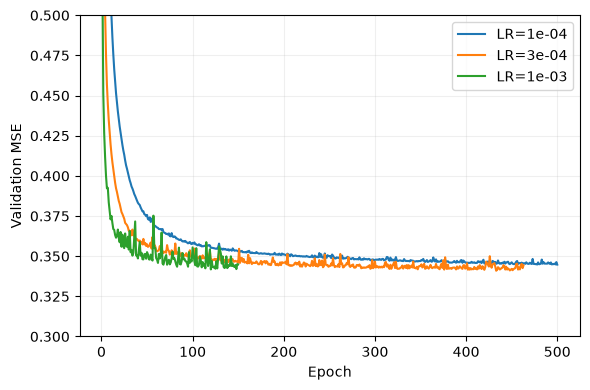

In [35]:

# Compare Frozen PepBERT learning curves
fig, ax = plt.subplots(figsize=(6, 4))

for lr in LEARNING_RATES["frozen"]:
    name = f"FC1_LR{lr:.0e}_E500_P30_seed42.csv"
    path = RESULT_DIR / "training_history" / "frozen" / "EC" / "SOS" / name

    history = pd.read_csv(path)

    ax.plot(
        history["Epoch"],
        history["Validation_MSE"],
        label=f"LR={lr:.0e}"
    )
    
    plt.ylim(0.3, 0.5)

ax.set_xlabel("Epoch")
ax.set_ylabel("Validation MSE")
ax.legend()
ax.grid(alpha=0.2)


plt.tight_layout()
plt.show()


In [36]:
from itertools import product

# Build experiment list
experiments = [
    (mode, target, pooling, lr, seed)
    for mode in ABLATION_MODES
    for target, pooling in CONFIGS
    for lr in LEARNING_RATES[mode]
    for seed in SEEDS
]

result_path = RESULT_DIR / "grid_search_results.csv"

# Load previous results
if result_path.exists():
    results = pd.read_csv(result_path).to_dict("records")
else:
    results = []

keys = ["Mode", "Dataset", "Pooling", "Learning_Rate", "Seed"]

# Run all experiments
with tqdm(
    experiments,
    desc="Ablation Grid Search",
    unit="run",
    position=0,
    dynamic_ncols=True
) as progress:

    for mode, target, pooling, lr, seed in progress:
        progress.set_postfix(
            mode=mode,
            target=target,
            pooling=pooling,
            lr=f"{lr:.0e}",
            seed=seed
        )

        result = train_ablation(
            mode=mode,
            target=target,
            pooling=pooling,
            lr=lr,
            seed=seed
        )

        results.append(result)

        # Save after every completed experiment
        result_df = pd.DataFrame(results)
        result_df = result_df.drop_duplicates(
            subset=keys,
            keep="last"
        )

        result_df.to_csv(result_path, index=False)
        results = result_df.to_dict("records")

print("\nAblation Grid Search completed")
print(f"Experiments: {len(result_df)} / {len(experiments)}")
print(f"Saved: {result_path}")


Ablation Grid Search:   0%|          | 0/120 [00:00<?, ?run/s]

frozen | EC | SOS | LR=1e-04 | Seed=43:   0%|          | 0/500 [00:00<?, ?epoch/s]

Train:   0%|          | 0/214 [00:00<?, ?batch/s]

Train:   0%|          | 0/214 [00:00<?, ?batch/s]

Train:   0%|          | 0/214 [00:00<?, ?batch/s]

Train:   0%|          | 0/214 [00:00<?, ?batch/s]

... (16,191 outputs left out)

Train:   0%|          | 0/186 [00:00<?, ?batch/s]

Train:   0%|          | 0/186 [00:00<?, ?batch/s]

Train:   0%|          | 0/186 [00:00<?, ?batch/s]


Ablation Grid Search completed
Experiments: 120 / 120
Saved: c:\Users\jinwo\Desktop\PepBert_REV\results\pepbert_ablation\grid_search_results.csv


In [37]:

# Load grid search results
grid_df = pd.read_csv(RESULT_DIR / "grid_search_results.csv")

groups = ["Mode", "Dataset", "Pooling", "Learning_Rate"]
expected_runs = len(CONFIGS) * len(SEEDS) * sum(
    len(LEARNING_RATES[mode]) for mode in ABLATION_MODES
)

# Check completed experiments
grid_df = grid_df.drop_duplicates(
    subset=groups + ["Seed"],
    keep="last"
)

if len(grid_df) != expected_runs:
    raise ValueError(
        f"Incomplete grid search: {len(grid_df)} / {expected_runs} experiments"
    )

# Summarize validation MSE across five seeds
validation_summary = (
    grid_df.groupby(groups)["Validation_MSE"]
    .agg(["mean", "std", "count"])
    .reset_index()
    .rename(columns={
        "mean": "Mean_MSE",
        "std": "SD_MSE",
        "count": "N_Seeds"
    })
)

if not (validation_summary["N_Seeds"] == len(SEEDS)).all():
    raise ValueError("Some conditions have incomplete seed results.")

validation_summary.to_csv(
    RESULT_DIR / "grid_search_summary.csv",
    index=False
)

# Select best learning rate
best_lr = (
    validation_summary
    .sort_values(["Mode", "Dataset", "Pooling", "Mean_MSE", "Learning_Rate"])
    .drop_duplicates(["Mode", "Dataset", "Pooling"])
    .reset_index(drop=True)
)

best_lr.to_csv(
    RESULT_DIR / "best_hyperparameters.csv",
    index=False
)

print("Best learning rates")
print(best_lr.to_string(index=False, float_format=lambda x: f"{x:.6f}"))

print("\nSaved:")
print("grid_search_summary.csv")
print("best_hyperparameters.csv")


Best learning rates
  Mode Dataset Pooling  Learning_Rate  Mean_MSE   SD_MSE  N_Seeds
frozen      EC    Mean       0.000100  0.284280 0.031064        5
frozen      EC     SOS       0.001000  0.335019 0.025400        5
frozen      SA    Mean       0.001000  0.334927 0.021467        5
frozen      SA     SOS       0.000100  0.284301 0.009252        5
random      EC    Mean       0.000100  0.293867 0.034472        5
random      EC     SOS       0.000100  0.277178 0.027982        5
random      SA    Mean       0.000030  0.294681 0.012055        5
random      SA     SOS       0.000030  0.295576 0.012632        5

Saved:
grid_search_summary.csv
best_hyperparameters.csv


In [38]:

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from scipy.stats import pearsonr, kendalltau
from torch.utils.data import DataLoader, Subset


def calculate_metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)

    return {
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "MAE": mean_absolute_error(y_true, y_pred),
        "R2": r2_score(y_true, y_pred),
        "PCC": pearsonr(y_true, y_pred).statistic,
        "KTC": kendalltau(y_true, y_pred).statistic
    }


def evaluate_ablation(mode, target, pooling, lr, seed, split):
    config = CONFIGS[(target, pooling)]

    # Load selected checkpoint
    name = (
        f"FC{config['fc_layers']}_LR{lr:.0e}_"
        f"E{MAX_EPOCHS}_P{PATIENCE}_seed{seed}"
    )

    model_path = MODEL_DIR / mode / target / pooling / f"{name}.pt"

    if not model_path.exists():
        raise FileNotFoundError(model_path)

    checkpoint = torch.load(
        model_path, map_location="cpu", weights_only=True
    )

    # Restore model
    model = build_ablation_model(
        mode, target, pooling, seed,
        model_module, pretrained_config, tokenizer, pretrained_weights
    )

    model.load_state_dict(checkpoint["model_state_dict"], strict=True)
    model.eval()

    # Select evaluation dataset
    if split == "Validation":
        _, val_idx = validation_splits[(target, seed)]
        dataset = Subset(peptide_datasets[(target, "Train")], val_idx)

    elif split == "Test":
        dataset = peptide_datasets[(target, "Test")]

    else:
        raise ValueError(f"Unknown split: {split}")

    loader = DataLoader(
        dataset,
        batch_size=pepbert_config.BATCH_SIZE,
        shuffle=False
    )

    # Predict pMIC
    y_true, y_pred = [], []

    with torch.inference_mode():
        for batch in loader:
            ids = batch["input_ids"].to(DEVICE)
            mask = batch["attention_mask"].to(DEVICE)

            predictions = model(ids, mask)

            y_true.extend(batch["labels"].numpy())
            y_pred.extend(predictions.cpu().numpy())

    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    metrics = calculate_metrics(y_true, y_pred)

    result = {
        "Mode": mode,
        "Dataset": target,
        "Pooling": pooling,
        "Learning_Rate": lr,
        "Seed": seed,
        "Split": split,
        **metrics
    }

    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return result, y_true, y_pred


In [39]:

# Load selected learning rates
best_lr = pd.read_csv(RESULT_DIR / "best_hyperparameters.csv")

evaluation_results = []
metrics = ["MSE", "RMSE", "MAE", "R2", "PCC", "KTC"]

# Evaluate all selected models
for row in tqdm(
    best_lr.itertuples(index=False),
    total=len(best_lr),
    desc="Ablation Evaluation",
    unit="model"
):
    for seed in SEEDS:
        for split in ["Validation", "Test"]:

            result, y_true, y_pred = evaluate_ablation(
                mode=row.Mode,
                target=row.Dataset,
                pooling=row.Pooling,
                lr=row.Learning_Rate,
                seed=seed,
                split=split
            )

            evaluation_results.append(result)

            # Save predictions
            prediction_dir = (
                RESULT_DIR / "predictions" /
                row.Mode / row.Dataset / row.Pooling
            )
            prediction_dir.mkdir(parents=True, exist_ok=True)

            prediction_df = pd.DataFrame({
                "Actual_pMIC": y_true,
                "Predicted_pMIC": y_pred
            })

            prediction_df.to_csv(
                prediction_dir / f"{split}_seed{seed}.csv",
                index=False
            )

            # Save evaluation results
            pd.DataFrame(evaluation_results).to_csv(
                RESULT_DIR / "evaluation_results.csv",
                index=False
            )

# Summarize across five seeds
evaluation_df = pd.DataFrame(evaluation_results)

summary = (
    evaluation_df
    .groupby(["Mode", "Dataset", "Pooling", "Split"])[metrics]
    .agg(["mean", "std"])
)

summary.columns = [
    f"{metric}_{stat.upper()}"
    for metric, stat in summary.columns
]

summary = summary.reset_index()

summary.to_csv(
    RESULT_DIR / "evaluation_summary.csv",
    index=False
)

print("\nEvaluation Summary")
print(summary.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

print("\nSaved:")
print("evaluation_results.csv")
print("evaluation_summary.csv")
print("predictions/")


Ablation Evaluation:   0%|          | 0/8 [00:00<?, ?model/s]


Evaluation Summary
  Mode Dataset Pooling      Split  MSE_MEAN  MSE_STD  RMSE_MEAN  RMSE_STD  MAE_MEAN  MAE_STD  R2_MEAN  R2_STD  PCC_MEAN  PCC_STD  KTC_MEAN  KTC_STD
frozen      EC    Mean       Test    0.3096   0.0035     0.5564    0.0031    0.4314   0.0031   0.3652  0.0072    0.6096   0.0059    0.4105   0.0072
frozen      EC    Mean Validation    0.2843   0.0311     0.5325    0.0292    0.4115   0.0190   0.4227  0.0524    0.6539   0.0381    0.4409   0.0192
frozen      EC     SOS       Test    0.3434   0.0012     0.5860    0.0010    0.4576   0.0010   0.2959  0.0025    0.5458   0.0028    0.3633   0.0028
frozen      EC     SOS Validation    0.3350   0.0254     0.5785    0.0219    0.4533   0.0139   0.3193  0.0388    0.5660   0.0329    0.3694   0.0173
frozen      SA    Mean       Test    0.3405   0.0013     0.5835    0.0011    0.4583   0.0017   0.1820  0.0031    0.4476   0.0034    0.2794   0.0035
frozen      SA    Mean Validation    0.3349   0.0215     0.5785    0.0182    0.4581   0.0116

In [40]:

# Load original fine-tuned evaluation results
original_dir = ROOT / "results" / "ml_vs_pepbert"

original_val = pd.read_csv(original_dir / "validation_results.csv")
original_test = pd.read_csv(original_dir / "test_results.csv")

print("=== Validation ===")
print("Columns:", original_val.columns.tolist())
print(original_val.head(3).to_string(index=False))

print("\n=== Test ===")
print("Columns:", original_test.columns.tolist())
print(original_test.head(3).to_string(index=False))


=== Validation ===
Columns: ['Dataset', 'Model', 'Feature', 'Seed', 'MSE', 'RMSE', 'MAE', 'R2', 'PCC', 'KTC']
Dataset Model Feature  Seed      MSE     RMSE      MAE       R2      PCC      KTC
     EC    DT QSOrder    42 0.431529 0.656909 0.500640 0.097656 0.422870 0.272765
     EC    DT QSOrder    43 0.381365 0.617547 0.473885 0.264339 0.532821 0.337317
     EC    DT QSOrder    44 0.361581 0.601316 0.477198 0.268675 0.536935 0.310708

=== Test ===
Columns: ['Dataset', 'Model', 'Feature', 'Seed', 'MSE', 'RMSE', 'MAE', 'R2', 'PCC', 'KTC']
Dataset Model Feature  Seed      MSE     RMSE      MAE       R2      PCC      KTC
     EC    DT QSOrder    42 0.413732 0.643220 0.493707 0.151682 0.454677 0.284926
     EC    DT QSOrder    43 0.399318 0.631916 0.485822 0.181237 0.468111 0.285323
     EC    DT QSOrder    44 0.397313 0.630328 0.483750 0.185348 0.466145 0.297135


In [41]:

# Combine ablation and fine-tuned results
metrics = ["MSE", "RMSE", "MAE", "R2", "PCC", "KTC"]

# Load ablation evaluation
ablation_df = pd.read_csv(RESULT_DIR / "evaluation_results.csv")

# Extract original PepBERT results
original_df = pd.concat([
    original_val.assign(Split="Validation"),
    original_test.assign(Split="Test")
], ignore_index=True)

model_labels = (
    original_df["Model"].astype(str) + " " +
    original_df["Feature"].fillna("").astype(str)
).str.lower()

original_df = original_df[
    model_labels.str.contains("pepbert")
].copy()

if original_df.empty:
    raise ValueError(
        "PepBERT results not found. "
        f"Available models: {pd.concat([original_val, original_test])['Model'].unique().tolist()}"
    )

# Identify pooling method
labels = (
    original_df["Model"].astype(str) + " " +
    original_df["Feature"].fillna("").astype(str)
).str.lower()

original_df["Pooling"] = np.select(
    [labels.str.contains("sos"), labels.str.contains("mean")],
    ["SOS", "Mean"],
    default=""
)

if (original_df["Pooling"] == "").any():
    raise ValueError(
        "Cannot identify pooling method: "
        f"{original_df[['Model', 'Feature']].drop_duplicates().to_dict('records')}"
    )

original_df["Mode"] = "fine-tuned"

# Keep comparable columns
columns = ["Mode", "Dataset", "Pooling", "Seed", "Split"] + metrics

combined = pd.concat([
    ablation_df[columns],
    original_df[columns]
], ignore_index=True)

# Verify five seeds for every comparison
groups = ["Dataset", "Pooling", "Mode", "Split"]

counts = combined.groupby(groups)["Seed"].agg(["count", "nunique"])

if not ((counts["count"] == 5) & (counts["nunique"] == 5)).all():
    raise ValueError(
        "Expected five unique seeds per group.\n"
        + counts.to_string()
    )

if len(counts) != 24:
    raise ValueError(f"Expected 24 groups, found {len(counts)}.")

# Save seed-level results
combined.to_csv(
    RESULT_DIR / "ablation_comparison_seed.csv",
    index=False
)

# Calculate mean and standard deviation
summary = combined.groupby(groups)[metrics].agg(["mean", "std"])

summary.columns = [
    f"{metric}_{stat.upper()}"
    for metric, stat in summary.columns
]

summary = summary.reset_index()

summary.to_csv(
    RESULT_DIR / "ablation_comparison.csv",
    index=False
)

# Format publication table
table = summary[groups].copy()

for metric in metrics:
    table[metric] = (
        summary[f"{metric}_MEAN"].map("{:.4f}".format)
        + " ± "
        + summary[f"{metric}_STD"].map("{:.4f}".format)
    )

table.to_csv(
    RESULT_DIR / "ablation_comparison_table.csv",
    index=False
)

print("Ablation Comparison — Test")
print(
    table[table["Split"] == "Test"]
    .to_string(index=False)
)

print("\nSaved:")
print("ablation_comparison_seed.csv")
print("ablation_comparison.csv")
print("ablation_comparison_table.csv")


Ablation Comparison — Test
Dataset Pooling       Mode Split             MSE            RMSE             MAE              R2             PCC             KTC
     EC    Mean fine-tuned  Test 0.2682 ± 0.0126 0.5177 ± 0.0121 0.3923 ± 0.0074 0.4501 ± 0.0259 0.6809 ± 0.0161 0.4764 ± 0.0112
     EC    Mean     frozen  Test 0.3096 ± 0.0035 0.5564 ± 0.0031 0.4314 ± 0.0031 0.3652 ± 0.0072 0.6096 ± 0.0059 0.4105 ± 0.0072
     EC    Mean     random  Test 0.3065 ± 0.0168 0.5535 ± 0.0150 0.4271 ± 0.0090 0.3715 ± 0.0345 0.6225 ± 0.0215 0.4160 ± 0.0138
     EC     SOS fine-tuned  Test 0.2591 ± 0.0087 0.5090 ± 0.0086 0.3826 ± 0.0119 0.4687 ± 0.0178 0.6888 ± 0.0107 0.4892 ± 0.0158
     EC     SOS     frozen  Test 0.3434 ± 0.0012 0.5860 ± 0.0010 0.4576 ± 0.0010 0.2959 ± 0.0025 0.5458 ± 0.0028 0.3633 ± 0.0028
     EC     SOS     random  Test 0.2896 ± 0.0057 0.5381 ± 0.0053 0.4102 ± 0.0075 0.4063 ± 0.0117 0.6478 ± 0.0072 0.4442 ± 0.0115
     SA    Mean fine-tuned  Test 0.2646 ± 0.0170 0.5142 ± 0.0164 0.387

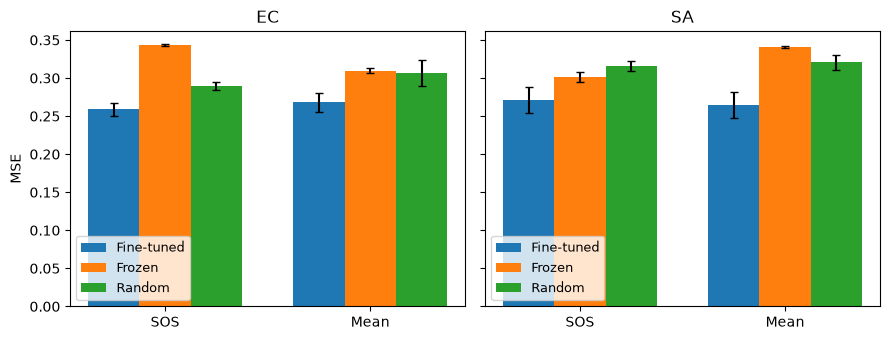

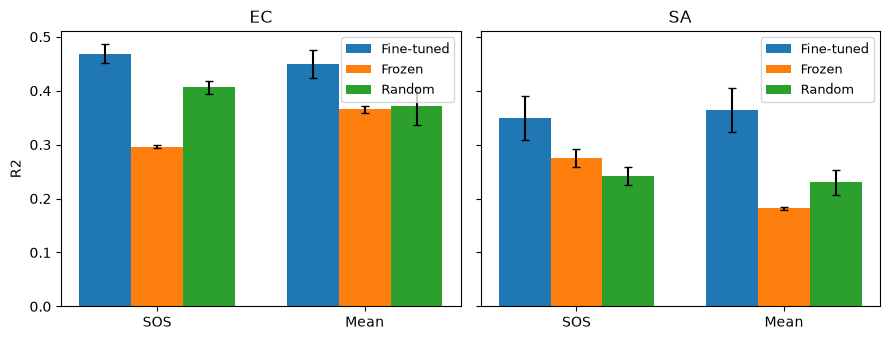

In [42]:

# Plot ablation performance
plot_df = pd.read_csv(RESULT_DIR / "ablation_comparison.csv")
plot_df = plot_df[plot_df["Split"] == "Test"].copy()

model_order = ["fine-tuned", "frozen", "random"]
labels = ["Fine-tuned", "Frozen", "Random"]

fig_dir = RESULT_DIR / "figures"
fig_dir.mkdir(parents=True, exist_ok=True)

for metric in ["MSE", "R2"]:
    fig, axes = plt.subplots(1, 2, figsize=(9, 3.5), sharey=True)

    for ax, target in zip(axes, ["EC", "SA"]):
        subset = plot_df[plot_df["Dataset"] == target]

        x = np.arange(2)
        width = 0.25

        for i, mode in enumerate(model_order):
            values = [
                subset[
                    (subset["Pooling"] == pooling) &
                    (subset["Mode"] == mode)
                ][f"{metric}_MEAN"].iloc[0]
                for pooling in ["SOS", "Mean"]
            ]

            errors = [
                subset[
                    (subset["Pooling"] == pooling) &
                    (subset["Mode"] == mode)
                ][f"{metric}_STD"].iloc[0]
                for pooling in ["SOS", "Mean"]
            ]

            ax.bar(
                x + (i - 1) * width,
                values,
                width,
                yerr=errors,
                capsize=3,
                label=labels[i]
            )

        ax.set_title(target)
        ax.set_xticks(x)
        ax.set_xticklabels(["SOS", "Mean"])
        ax.set_ylabel(metric if target == "EC" else "")
        ax.legend(fontsize=9)

    plt.tight_layout()
    plt.savefig(fig_dir / f"Ablation_{metric}.png", dpi=300)
    plt.show()


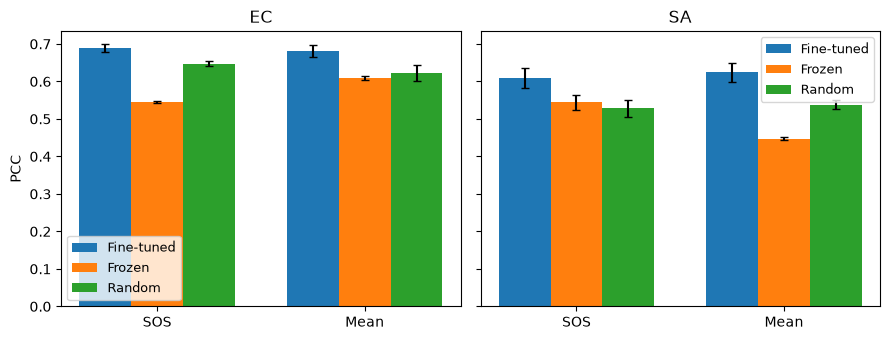

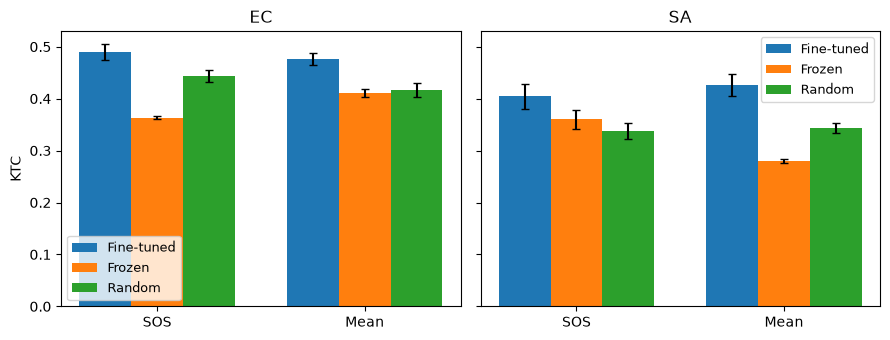

In [43]:

# Plot PCC and KTC comparisons
plot_df = pd.read_csv(RESULT_DIR / "ablation_comparison.csv")
plot_df = plot_df[plot_df["Split"] == "Test"].copy()

model_order = ["fine-tuned", "frozen", "random"]
labels = ["Fine-tuned", "Frozen", "Random"]

for metric in ["PCC", "KTC"]:
    fig, axes = plt.subplots(1, 2, figsize=(9, 3.5), sharey=True)

    for ax, target in zip(axes, ["EC", "SA"]):
        subset = plot_df[plot_df["Dataset"] == target]
        x = np.arange(2)
        width = 0.25

        for i, mode in enumerate(model_order):
            values = []
            errors = []

            for pooling in ["SOS", "Mean"]:
                row = subset[
                    (subset["Pooling"] == pooling) &
                    (subset["Mode"] == mode)
                ].iloc[0]

                values.append(row[f"{metric}_MEAN"])
                errors.append(row[f"{metric}_STD"])

            ax.bar(
                x + (i - 1) * width,
                values,
                width,
                yerr=errors,
                capsize=3,
                label=labels[i]
            )

        ax.set_title(target)
        ax.set_xticks(x)
        ax.set_xticklabels(["SOS", "Mean"])
        ax.set_ylabel(metric if target == "EC" else "")
        ax.legend(fontsize=9)

    plt.tight_layout()
    plt.savefig(
        RESULT_DIR / "figures" / f"Ablation_{metric}.png",
        dpi=300
    )
    plt.show()
